<div style="background:linear-gradient(115deg,#102c64,#6337ac,#b52d8b);padding:26px;border-radius:16px;color:white">
<p style="letter-spacing:2px;color:#ebe2ff">🐼 CURSOS PyM · CURSO INTERMEDIO</p>
<h1 style="color:white;margin:8px 0">Caso de uso 02 · Cafetería: cerrar cifras sin perder ventas</h1>
<p style="font-size:19px;color:white">Del archivo de caja con errores a un cierre conciliado para operaciones</p>
<p>Python + pandas + SQL · Del insumo al reporte que recibe el área</p>
</div>

# Cafetería: cerrar cifras sin perder ventas
**Guía resuelta y comentada · Acompañamiento paso a paso · Datos ficticios**

Esta libreta consolida las tareas 2 y 3 del curso. Vamos a recorrer juntos
las decisiones, el código y la interpretación de un encargo de trabajo.
Cada bloque contiene su desarrollo completo y explica para qué sirve.

**Cómo recorrerla:** abre una copia en Google Colab o Jupyter y ejecuta las
celdas de arriba hacia abajo. Los datos están incluidos; no necesitas descargar
archivos, instalar librerías adicionales ni tener una base de datos previa.
Las tablas y los mensajes ya están resueltos para acompañar la explicación.

**Nuestro recorrido:** entender → explorar → preparar → consultar → validar → comunicar.

| Símbolo | Nos acompaña para… |
|---|---|
| 🥸🧪 | Pensar y decidir como analistas. |
| 🚀 | Recorrer el código y sus resultados. |
| 👀 | Detenernos a interpretar una decisión. |
| 🔥 | Retener una conclusión del proceso. |
| 🤖 | Usar IA con contexto y verificar su ayuda. |


## 1. 🥸🧪 Son las 9:00: operaciones necesita un cierre confiable

Imaginemos que recibimos una muestra exportada del sistema de caja. La persona de
operaciones quiere revisar enero y febrero, pero detectó textos donde esperaba números,
una carga repetida y datos incompletos. Nuestro primer trabajo es averiguar qué podemos
recuperar y qué debe quedar identificado como desconocido.

> **El encargo:** «Prepara el ingreso por periodo, incluyendo el que no tiene fecha.
> Revisa las ventas de febrero para llevar. Después, cruza las ventas con el menú:
> necesitamos ver todos sus productos y comprobar que el cruce no haga desaparecer ingresos».

El proyecto de cafetería nos enseña a **conservar información útil sin inventar la que
falta**, convertir una limpieza en una herramienta reutilizable y conciliar cada reporte.

| Momento del trabajo | Qué vamos a dejar listo |
|---|---|
| Recibir y entender | Unidad de registro, reglas y diagnóstico del insumo. |
| Preparar con Python | Ventas depuradas y función de limpieza documentada. |
| Consultar con SQL | Cierre por periodo, detalle solicitado y menú completo. |
| Validar | Controles de ingresos, cantidades y cobertura de las uniones. |
| Comunicar | CSV, nota a operaciones y acciones sobre la captura. |

Esta es una muestra ficticia y no un calendario completo. Sus importes están en
**unidades monetarias (UM)**. Una diferencia entre enero y febrero describe esta muestra;
por sí sola no demuestra un cambio en las ventas del negocio.


## 2. Antes del código: acordamos qué cuenta cada cifra

**Una fila representa una transacción de un solo producto.** `Transaction ID` es su
identificador. En este insumo, la fila idéntica repetida es una carga duplicada.

| Campo de origen | Significado | Cuidado al interpretarlo |
|---|---|---|
| `Transaction ID` | Identificador de la venta. | Contar filas solo equivale a contar ventas después de depurar. |
| `Item` | Producto vendido. | No adivinamos el producto por su precio. |
| `Quantity` | Piezas vendidas. | Una cantidad faltante no significa cero piezas. |
| `Price Per Unit` | Precio por pieza en UM. | El menú tiene precios fijos y positivos. |
| `Total Spent` | Ingreso de la transacción en UM. | Es el indicador principal del cierre. |
| `Payment Method`, `Location` | Medio de pago y modalidad de consumo. | Los desconocidos se identifican explícitamente. |
| `Transaction Date` | Fecha de la venta. | Una fecha inválida no autoriza a borrar un ingreso conocido. |

Las reglas de esta simulación permiten usar `total = cantidad × precio`: no hay descuentos
ni cargos extra y las cantidades conocidas son enteros positivos. Recuperamos un dato
únicamente cuando esas reglas lo permiten. Separamos **ventas, piezas e ingresos**.


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#f7f5fc",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#26213f", "text.color": "#26213f",
                     "font.size": 11})
COLORES_PYM = ["#6337ac", "#2366bc", "#c22c91", "#33a9bf", "#9b70d4"]
carpeta_trabajo = Path.cwd() / "pym_cafeteria"
carpeta_salida = carpeta_trabajo / "entregables"
carpeta_salida.mkdir(parents=True, exist_ok=True)
ruta_bd = carpeta_trabajo / "analisis.db"

def consultar(query):
    """Ejecuta SQL, devuelve un DataFrame y siempre cierra la conexión."""
    conexion = sqlite3.connect(str(ruta_bd))
    try:
        return pd.read_sql_query(query, conexion)
    finally:
        conexion.close()

print("Entorno listo. Ejecuta el siguiente bloque para recibir el insumo.")
print("Base SQLite:", ruta_bd)
print("Entregables:", carpeta_salida)


Entorno listo. Ejecuta el siguiente bloque para recibir el insumo.
Base SQLite: /workspace/scratch/a72119b51a6b/work/run_cafeteria/pym_cafeteria/analisis.db
Entregables: /workspace/scratch/a72119b51a6b/work/run_cafeteria/pym_cafeteria/entregables


## 3. 🚀 Recibimos el archivo y el menú de referencia

Creamos dentro de la libreta los mismos datos de las tareas. Así podemos recorrer el
caso completo sin archivos externos. El menú aporta precios, no información para asignar
un producto cuando solo conocemos su importe.


In [2]:
import pandas as pd
import numpy as np

# Insumo recibido: todas las cantidades e importes se entregaron como texto.
df_crudo_cafe = pd.DataFrame(
    [
        ('T01', 'Coffee',   '3',       '2',       '6',       'Cash',    'Takeaway', '2026-01-05'),
        ('T02', 'Tea',      '4',       'UNKNOWN', '6',       'Card',    'In-store', '2026-01-07'),
        ('T03', 'Sandwich', '2',       '4',       'ERROR',   'Card',    'Takeaway', '2026-01-10'),
        ('T04', 'Cake',     'UNKNOWN', '3',       '9',       'Cash',    'In-store', '2026-01-12'),
        ('T05', 'UNKNOWN',  '2',       'ERROR',   '6',       'Cash',    'Takeaway', '2026-01-15'),
        ('T06', 'Cookie',   '5',       '1',       '5',       'UNKNOWN', 'Takeaway', '2026-02-02'),
        ('T07', 'Coffee',   'ERROR',   '2',       'UNKNOWN', 'Cash',    'In-store', '2026-02-05'),
        ('T08', 'Juice',    '2',       '3',       '6',       'Card',    'UNKNOWN',  '2026-02-08'),
        ('T09', 'Salad',    '1',       '5',       '5',       'Card',    'In-store', 'ERROR'),
        ('T10', 'ERROR',    'UNKNOWN', 'UNKNOWN', '7',       'UNKNOWN', 'UNKNOWN',  '2026-02-14'),
        ('T11', 'Smoothie', '3',       '4',       '12',      'Card',    'Takeaway', '2026-02-16'),
        ('T12', 'Coffee',   '2',       '2',       '4',       'Cash',    'In-store', '2026-01-20'),
        ('T13', 'Tea',      '2',       '1.5',     '3',       'Cash',    'Takeaway', '2026-01-25'),
        ('T14', 'Sandwich', '1',       '4',       '4',       'Card',    'In-store', '2026-02-22'),
        ('T01', 'Coffee',   '3',       '2',       '6',       'Cash',    'Takeaway', '2026-01-05'),
    ],
    columns=['Transaction ID', 'Item', 'Quantity', 'Price Per Unit',
             'Total Spent', 'Payment Method', 'Location', 'Transaction Date']
)

precios_cafe = {
    'Coffee': 2.0, 'Tea': 1.5, 'Sandwich': 4.0, 'Salad': 5.0,
    'Cake': 3.0, 'Cookie': 1.0, 'Smoothie': 4.0, 'Juice': 3.0
}

display(df_crudo_cafe)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,T01,Coffee,3,2,6,Cash,Takeaway,2026-01-05
1,T02,Tea,4,UNKNOWN,6,Card,In-store,2026-01-07
2,T03,Sandwich,2,4,ERROR,Card,Takeaway,2026-01-10
3,T04,Cake,UNKNOWN,3,9,Cash,In-store,2026-01-12
4,T05,UNKNOWN,2,ERROR,6,Cash,Takeaway,2026-01-15
5,T06,Cookie,5,1,5,UNKNOWN,Takeaway,2026-02-02
6,T07,Coffee,ERROR,2,UNKNOWN,Cash,In-store,2026-02-05
7,T08,Juice,2,3,6,Card,UNKNOWN,2026-02-08
8,T09,Salad,1,5,5,Card,In-store,ERROR
9,T10,ERROR,UNKNOWN,UNKNOWN,7,UNKNOWN,UNKNOWN,2026-02-14


## 4. Exploramos antes de modificar

Las primeras filas ayudan a orientarnos, pero no bastan: revisamos tamaño, tipos y
marcadores en todas las columnas. `isna()` todavía no detecta textos como `ERROR`.
Guardamos además una copia para comprobar después que el original permaneció intacto.


In [3]:
crudo_respaldo = df_crudo_cafe.copy(deep=True)
print("Filas recibidas:", df_crudo_cafe.shape[0])
print("Transacciones distintas:", df_crudo_cafe["Transaction ID"].nunique())
print("Filas exactamente repetidas:", int(df_crudo_cafe.duplicated().sum()))
df_crudo_cafe.info()
diagnostico = pd.DataFrame({
    "TipoRecibido": df_crudo_cafe.dtypes.astype(str),
    "NulosReconocidos": df_crudo_cafe.isna().sum(),
    "MarcadoresError": [int(df_crudo_cafe[c].isin(["ERROR", "UNKNOWN"]).sum())
                        for c in df_crudo_cafe.columns]
})
display(diagnostico)


Filas recibidas: 15
Transacciones distintas: 14
Filas exactamente repetidas: 1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    15 non-null     object
 1   Item              15 non-null     object
 2   Quantity          15 non-null     object
 3   Price Per Unit    15 non-null     object
 4   Total Spent       15 non-null     object
 5   Payment Method    15 non-null     object
 6   Location          15 non-null     object
 7   Transaction Date  15 non-null     object
dtypes: object(8)
memory usage: 1.1+ KB


,TipoRecibido,NulosReconocidos,MarcadoresError
Transaction ID,object,0,0
Item,object,0,2
Quantity,object,0,3
Price Per Unit,object,0,3
Total Spent,object,0,2
Payment Method,object,0,2
Location,object,0,2
Transaction Date,object,0,1


👀 **Lectura del diagnóstico.** Recibimos 15 filas, pero solo 14 identificadores
distintos. Las cantidades y los importes llegaron como texto. Los marcadores son
faltantes de negocio aunque todavía no sean nulos reconocidos por pandas.

La cantidad de identificadores únicos ayuda a detectar el problema; para retirar la
carga repetida utilizamos la regla acordada: **duplicado exacto**, no cualquier fila
parecida ni cualquier transacción del mismo producto.


In [4]:
display(df_crudo_cafe[df_crudo_cafe.duplicated(keep=False)])
df_preparacion = df_crudo_cafe.drop_duplicates().copy()
df_preparacion.columns = list(map(lambda nombre: nombre.replace(" ", "_"),
                                 df_preparacion.columns))
assert df_preparacion["Transaction_ID"].is_unique
print("Tras retirar la carga repetida:", len(df_preparacion), "transacciones")
display(df_preparacion.head())


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,T01,Coffee,3,2,6,Cash,Takeaway,2026-01-05
14,T01,Coffee,3,2,6,Cash,Takeaway,2026-01-05


Tras retirar la carga repetida: 14 transacciones


,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
0,T01,Coffee,3,2,6,Cash,Takeaway,2026-01-05
1,T02,Tea,4,UNKNOWN,6,Card,In-store,2026-01-07
2,T03,Sandwich,2,4,ERROR,Card,Takeaway,2026-01-10
3,T04,Cake,UNKNOWN,3,9,Cash,In-store,2026-01-12
4,T05,UNKNOWN,2,ERROR,6,Cash,Takeaway,2026-01-15


## 5. Reconocemos faltantes y convertimos los números

Primero cambiamos `ERROR` y `UNKNOWN` por `np.nan`. Después `astype(float)` puede
convertir cantidades e importes. El ciclo evita repetir la misma instrucción por columna.
Este orden responde al formato concreto del archivo recibido.


In [5]:
for columna in df_preparacion.columns:
    df_preparacion[columna] = df_preparacion[columna].map(
        lambda valor: np.nan if valor == "ERROR" or valor == "UNKNOWN" else valor
    )
for columna in ["Quantity", "Price_Per_Unit", "Total_Spent"]:
    df_preparacion[columna] = df_preparacion[columna].astype(float)

display(df_preparacion[["Transaction_ID", "Item", "Quantity", "Price_Per_Unit", "Total_Spent"]])
print("Faltantes numéricos antes de recuperar:")
display(df_preparacion[["Quantity", "Price_Per_Unit", "Total_Spent"]].isna().sum())


,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent
0,T01,Coffee,3.0,2.0,6.0
1,T02,Tea,4.0,NaN,6.0
2,T03,Sandwich,2.0,4.0,NaN
3,T04,Cake,NaN,3.0,9.0
4,T05,NaN,2.0,NaN,6.0
5,T06,Cookie,5.0,1.0,5.0
6,T07,Coffee,NaN,2.0,NaN
7,T08,Juice,2.0,3.0,6.0
8,T09,Salad,1.0,5.0,5.0
9,T10,NaN,NaN,NaN,7.0


Faltantes numéricos antes de recuperar:


Quantity          3
Price_Per_Unit    3
Total_Spent       2
dtype: int64

## 6. Recuperamos solo los valores deducibles

Seguimos cuatro vías y usamos `fillna`: un valor informado se conserva.

| Vía | Regla | Qué sucede en esta muestra |
|---|---|---|
| Precio por menú | Producto identificado → precio fijo. | T02 recupera el precio de Tea. |
| Total por multiplicación | Cantidad × precio. | T03 recupera su ingreso de 8 UM. |
| Cantidad por división | Total / precio. | T04 recupera 3 piezas de Cake. |
| Precio aún faltante | Total / cantidad. | T05 recupera precio de 3 UM, pero su producto sigue desconocido. |

👀 Un precio compartido no identifica un producto. T05 puede aportar ingreso al cierre
sin que sepamos qué se vendió. T10 aporta 7 UM aunque tampoco podamos recuperar sus piezas.


In [6]:
df_preparacion["Price_Per_Unit"] = df_preparacion["Price_Per_Unit"].fillna(
    df_preparacion["Item"].map(precios_cafe))
df_preparacion["Total_Spent"] = df_preparacion["Total_Spent"].fillna(
    df_preparacion["Quantity"] * df_preparacion["Price_Per_Unit"])
df_preparacion["Quantity"] = df_preparacion["Quantity"].fillna(
    df_preparacion["Total_Spent"] / df_preparacion["Price_Per_Unit"])
df_preparacion["Price_Per_Unit"] = df_preparacion["Price_Per_Unit"].fillna(
    df_preparacion["Total_Spent"] / df_preparacion["Quantity"])

display(df_preparacion[df_preparacion["Transaction_ID"].isin(["T02", "T03", "T04", "T05", "T07", "T10"])])


,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
1,T02,Tea,4.0,1.5,6.0,Card,In-store,2026-01-07
2,T03,Sandwich,2.0,4.0,8.0,Card,Takeaway,2026-01-10
3,T04,Cake,3.0,3.0,9.0,Cash,In-store,2026-01-12
4,T05,NaN,2.0,3.0,6.0,Cash,Takeaway,2026-01-15
6,T07,Coffee,NaN,2.0,NaN,Cash,In-store,2026-02-05
9,T10,NaN,NaN,NaN,7.0,NaN,NaN,2026-02-14


## 7. Decidimos qué conservar y hacemos visible lo desconocido

El reporte necesita un ingreso conocido o recuperable. T07 no cumple esa condición y
se aparta con una razón registrada. Su ingreso desconocido **no se reporta como cero**.
El resto se conserva aunque tenga limitaciones en otra columna.

`Int64`, con I mayúscula, permite guardar piezas enteras junto con faltantes. Para los
textos utilizamos `Desconocido`; para fechas usamos `errors="coerce"`, que deja `NaT`.


In [7]:
df_excluidas = df_preparacion[df_preparacion["Total_Spent"].isna()].copy()
df_excluidas["Motivo"] = "Ingreso total irrecuperable con las reglas disponibles"
df_pasos = df_preparacion.dropna(subset=["Total_Spent"]).copy()
df_pasos["Quantity"] = df_pasos["Quantity"].astype("Int64")
for columna in ["Item", "Payment_Method", "Location"]:
    df_pasos[columna] = df_pasos[columna].fillna("Desconocido")
df_pasos["Transaction_Date"] = pd.to_datetime(df_pasos["Transaction_Date"], errors="coerce")
df_pasos["Mes"] = df_pasos["Transaction_Date"].dt.month.astype("Int64")

print("Registro apartado y razón:")
display(df_excluidas[["Transaction_ID", "Item", "Total_Spent", "Motivo"]])
print("Ventas conservadas con limitaciones visibles:")
display(df_pasos[df_pasos["Transaction_ID"].isin(["T05", "T09", "T10"])])


Registro apartado y razón:


,Transaction_ID,Item,Total_Spent,Motivo
6,T07,Coffee,NaN,Ingreso total irrecuperable con las reglas dis...


Ventas conservadas con limitaciones visibles:


,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date,Mes
4,T05,Desconocido,2,3.0,6.0,Cash,Takeaway,2026-01-15,1
8,T09,Salad,1,5.0,5.0,Card,In-store,NaT,<NA>
9,T10,Desconocido,<NA>,NaN,7.0,Desconocido,Desconocido,2026-02-14,2


## 8. 🤖 Convertimos el procedimiento entendido en una función

Ya recorrimos las decisiones línea por línea. Ahora las reunimos para procesar el
siguiente archivo con las mismas reglas, sin editar el insumo recibido. La función
recibe datos y precios, trabaja sobre una copia y devuelve la tabla preparada.

Su alcance es el contrato de esta práctica: precios fijos positivos, importes sin
descuentos y cantidades enteras positivas. Un nuevo archivo con reglas distintas
necesitaría revisar el procedimiento antes de reutilizarlo.


In [8]:
def limpiar_ventas_cafe(df_cafe, precios_cafe):
    """Prepara un cierre de ingresos bajo las reglas de la cafetería de esta guía.

    Conserva el original, retira duplicados exactos y reconoce ERROR/UNKNOWN.
    Recupera solo faltantes deducibles; excluye el total irrecuperable.
    Conserva ingresos conocidos aunque falte cantidad, producto o fecha.
    """
    resultado = df_cafe.copy(deep=True)
    resultado.columns = list(map(lambda nombre: nombre.replace(" ", "_"), resultado.columns))
    resultado = resultado.drop_duplicates().copy()
    for columna in resultado.columns:
        resultado[columna] = resultado[columna].map(
            lambda valor: np.nan if valor == "ERROR" or valor == "UNKNOWN" else valor)
    for columna in ["Quantity", "Price_Per_Unit", "Total_Spent"]:
        resultado[columna] = resultado[columna].astype(float)

    resultado["Price_Per_Unit"] = resultado["Price_Per_Unit"].fillna(resultado["Item"].map(precios_cafe))
    resultado["Total_Spent"] = resultado["Total_Spent"].fillna(resultado["Quantity"] * resultado["Price_Per_Unit"])
    resultado["Quantity"] = resultado["Quantity"].fillna(resultado["Total_Spent"] / resultado["Price_Per_Unit"])
    resultado["Price_Per_Unit"] = resultado["Price_Per_Unit"].fillna(resultado["Total_Spent"] / resultado["Quantity"])

    resultado = resultado.dropna(subset=["Total_Spent"]).copy()
    resultado["Quantity"] = resultado["Quantity"].astype("Int64")
    for columna in ["Item", "Payment_Method", "Location"]:
        resultado[columna] = resultado[columna].fillna("Desconocido")
    resultado["Transaction_Date"] = pd.to_datetime(resultado["Transaction_Date"], errors="coerce")
    resultado["Mes"] = resultado["Transaction_Date"].dt.month.astype("Int64")
    return resultado

df_limpio_cafe = limpiar_ventas_cafe(df_crudo_cafe, precios_cafe)
pd.testing.assert_frame_equal(df_limpio_cafe, df_pasos)
pd.testing.assert_frame_equal(df_crudo_cafe, crudo_respaldo)
assert len(df_limpio_cafe) == 13
assert df_limpio_cafe["Transaction_ID"].is_unique
print("La función reproduce los pasos y conserva el original intacto.")


La función reproduce los pasos y conserva el original intacto.


## 9. Dejamos una bitácora que otro analista pueda revisar

La bitácora explica el movimiento de registros. **15 filas recibidas − 1 duplicado −
1 venta de total irrecuperable = 13 ventas conservadas.** El importe de la venta
apartada sigue desconocido: el cierre corresponde a los ingresos que sí pudimos sostener.


In [9]:
ingreso_global_python = float(df_limpio_cafe["Total_Spent"].sum())
auditoria_preparacion = pd.DataFrame({
    "Control": ["Filas recibidas", "Duplicados exactos retirados", "Transacciones únicas recibidas",
                "Ventas con total irrecuperable", "Ventas conservadas", "Ventas sin fecha",
                "Ventas sin cantidad", "Ventas con producto desconocido", "Ingreso conocido conservado (UM)"],
    "Valor": [len(df_crudo_cafe), int(df_crudo_cafe.duplicated().sum()),
              df_crudo_cafe["Transaction ID"].nunique(), len(df_excluidas), len(df_limpio_cafe),
              int(df_limpio_cafe["Transaction_Date"].isna().sum()),
              int(df_limpio_cafe["Quantity"].isna().sum()),
              int((df_limpio_cafe["Item"] == "Desconocido").sum()), ingreso_global_python]
})
display(auditoria_preparacion)
assert len(df_crudo_cafe) - int(df_crudo_cafe.duplicated().sum()) - len(df_excluidas) == len(df_limpio_cafe)
assert set(df_excluidas["Transaction_ID"]) == {"T07"}
assert pd.isna(df_limpio_cafe.loc[df_limpio_cafe["Transaction_ID"] == "T09", "Transaction_Date"].iloc[0])
assert pd.isna(df_limpio_cafe.loc[df_limpio_cafe["Transaction_ID"] == "T10", "Quantity"].iloc[0])


,Control,Valor
0,Filas recibidas,15.0
1,Duplicados exactos retirados,1.0
2,Transacciones únicas recibidas,14.0
3,Ventas con total irrecuperable,1.0
4,Ventas conservadas,13.0
5,Ventas sin fecha,1.0
6,Ventas sin cantidad,1.0
7,Ventas con producto desconocido,2.0
8,Ingreso conocido conservado (UM),81.0


## 10. Respondemos primero con las herramientas Python del curso

Construimos los tres periodos con filtros y sumas: enero, febrero y fecha desconocida.
La categoría `Sin fecha` permite conciliar todo el ingreso conservado. Si elimináramos
esa categoría, el cierre mensual explicaría menos dinero que el archivo preparado.


In [10]:
enero = df_limpio_cafe[df_limpio_cafe["Mes"] == 1]
febrero = df_limpio_cafe[df_limpio_cafe["Mes"] == 2]
sin_fecha = df_limpio_cafe[df_limpio_cafe["Transaction_Date"].isna()]
resumen_cafe = pd.DataFrame([
    {"Periodo": "Enero", "Tickets": len(enero), "Ingreso": enero["Total_Spent"].sum()},
    {"Periodo": "Febrero", "Tickets": len(febrero), "Ingreso": febrero["Total_Spent"].sum()},
    {"Periodo": "Sin fecha", "Tickets": len(sin_fecha), "Ingreso": sin_fecha["Total_Spent"].sum()}
])
display(resumen_cafe)
assert resumen_cafe["Tickets"].sum() == len(df_limpio_cafe)
assert np.isclose(resumen_cafe["Ingreso"].sum(), ingreso_global_python)
print("Cierre conciliado:", ingreso_global_python, "UM")


,Periodo,Tickets,Ingreso
0,Enero,7,42.0
1,Febrero,5,34.0
2,Sin fecha,1,5.0


Cierre conciliado: 81.0 UM


### La consulta puntual: febrero para llevar

Combinamos el periodo con `Location == "Takeaway"`. Una venta sin fecha no puede
asignarse a febrero, aunque su ingreso sí pertenezca al cierre global conservado.


In [11]:
febrero_para_llevar = df_limpio_cafe[
    (df_limpio_cafe["Mes"] == 2) & (df_limpio_cafe["Location"] == "Takeaway")
].copy()
display(febrero_para_llevar[["Transaction_ID", "Item", "Quantity", "Total_Spent", "Transaction_Date"]])
print("Ventas para llevar en febrero:", len(febrero_para_llevar))
print("Ingreso del segmento:", febrero_para_llevar["Total_Spent"].sum(), "UM")
ruta_resumen_python = carpeta_salida / "resumen_operaciones_cafe.csv"
resumen_cafe.to_csv(ruta_resumen_python, index=False)
resumen_releido = pd.read_csv(ruta_resumen_python)
pd.testing.assert_frame_equal(resumen_releido, resumen_cafe, check_dtype=False)
print("CSV exportado y releído: conserva periodos, tickets e ingreso.")


,Transaction_ID,Item,Quantity,Total_Spent,Transaction_Date
5,T06,Cookie,5,5.0,2026-02-02
10,T11,Smoothie,3,12.0,2026-02-16


Ventas para llevar en febrero: 2
Ingreso del segmento: 17.0 UM
CSV exportado y releído: conserva periodos, tickets e ingreso.


## 11. Python y SQL continúan el mismo trabajo

Python dejó los datos preparados. SQL nos permite consultar ese resultado, resumirlo
y relacionarlo con el menú. No volvemos a crear las ventas ni a limpiar otra versión:
guardamos la tabla que acabamos de validar.

Renombramos las columnas para que sus nombres expliquen el negocio y almacenamos las
fechas conocidas como texto ISO (`AAAA-MM-DD`), sin horas. `Periodo` ya está preparado
para agrupar con los temas vistos en el curso. Los faltantes se guardarán como `NULL`.


In [12]:
df_cafe_sql = df_limpio_cafe.rename(columns={
    "Transaction_ID": "VentaID", "Item": "Producto", "Quantity": "Cantidad",
    "Price_Per_Unit": "PrecioUnitario", "Total_Spent": "Ingreso",
    "Payment_Method": "MedioPago", "Location": "Modalidad", "Transaction_Date": "Fecha"
}).copy()
df_cafe_sql["Periodo"] = df_limpio_cafe["Mes"].map({1: "Enero", 2: "Febrero"}).fillna("Sin fecha")
df_cafe_sql["Fecha"] = df_cafe_sql["Fecha"].dt.strftime("%Y-%m-%d")
df_cafe_sql = df_cafe_sql[["VentaID", "Producto", "Cantidad", "PrecioUnitario", "Ingreso",
                         "MedioPago", "Modalidad", "Fecha", "Periodo"]]
df_menu = pd.DataFrame(list(precios_cafe.items()) + [("Muffin", 2.5)],
                       columns=["Producto", "PrecioMenu"])
display(df_cafe_sql.head())
display(df_menu)


,VentaID,Producto,Cantidad,PrecioUnitario,Ingreso,MedioPago,Modalidad,Fecha,Periodo
0,T01,Coffee,3,2.0,6.0,Cash,Takeaway,2026-01-05,Enero
1,T02,Tea,4,1.5,6.0,Card,In-store,2026-01-07,Enero
2,T03,Sandwich,2,4.0,8.0,Card,Takeaway,2026-01-10,Enero
3,T04,Cake,3,3.0,9.0,Cash,In-store,2026-01-12,Enero
4,T05,Desconocido,2,3.0,6.0,Cash,Takeaway,2026-01-15,Enero


,Producto,PrecioMenu
0,Coffee,2.0
1,Tea,1.5
2,Sandwich,4.0
3,Salad,5.0
4,Cake,3.0
5,Cookie,1.0
6,Smoothie,4.0
7,Juice,3.0
8,Muffin,2.5


### Creamos dos tablas con llaves validadas

En `ventas_cafe` cada `VentaID` debe ser único. En `menu_cafe` cada producto aparece
una vez: así, una venta no puede coincidir con dos filas del menú y duplicarse al unir.
**Muffin** es la ampliación de la tarea SQL y no tiene ventas en esta muestra.

`replace` restablece solo estas dos tablas de práctica al repetir el recorrido.
`append` agregaría otra copia y alteraría nuestros totales. `index=False` evita convertir
el índice técnico de pandas en una columna del negocio. Cerramos la conexión al terminar.


In [13]:
assert df_cafe_sql["VentaID"].is_unique
assert df_menu["Producto"].is_unique
conexion = sqlite3.connect(str(ruta_bd))
try:
    df_cafe_sql.to_sql("ventas_cafe", conexion, if_exists="replace", index=False)
    df_menu.to_sql("menu_cafe", conexion, if_exists="replace", index=False)
finally:
    conexion.close()

display(consultar("SELECT VentaID, Producto, Cantidad, Ingreso, Fecha FROM ventas_cafe ORDER BY VentaID LIMIT 5"))
display(consultar("SELECT DISTINCT Modalidad FROM ventas_cafe ORDER BY Modalidad"))
duplicados_sql = consultar("SELECT VentaID, COUNT(*) AS Filas FROM ventas_cafe GROUP BY VentaID HAVING COUNT(*) > 1")
assert duplicados_sql.empty
print("Tablas listas y sin identificadores de venta duplicados.")


,VentaID,Producto,Cantidad,Ingreso,Fecha
0,T01,Coffee,3,6.0,2026-01-05
1,T02,Tea,4,6.0,2026-01-07
2,T03,Sandwich,2,8.0,2026-01-10
3,T04,Cake,3,9.0,2026-01-12
4,T05,Desconocido,2,6.0,2026-01-15


,Modalidad
0,Desconocido
1,In-store
2,Takeaway


Tablas listas y sin identificadores de venta duplicados.


## 12. SQL: una cifra de control antes de cualquier reporte

`COUNT(*)` cuenta todas las ventas. `COUNT(Cantidad)` cuenta únicamente aquellas cuya
cantidad se conoce. `SUM(Cantidad)` suma piezas conocidas; no estima las desconocidas.
La misma distinción se mantendrá en cada resumen.


In [14]:
query_global = """
SELECT COUNT(*) AS Ventas,
       COUNT(Cantidad) AS VentasConCantidad,
       SUM(Cantidad) AS UnidadesConocidas,
       SUM(Ingreso) AS Ingreso
FROM ventas_cafe
"""
cafe_global = consultar(query_global)
display(cafe_global)
assert int(cafe_global.loc[0, "Ventas"]) == len(df_limpio_cafe)
assert np.isclose(cafe_global.loc[0, "Ingreso"], ingreso_global_python)


,Ventas,VentasConCantidad,UnidadesConocidas,Ingreso
0,13,12,30,81.0


## 13. SQL: el cierre por periodo y su conciliación

`GROUP BY Periodo` cambia la unidad: cada fila del resultado representa un periodo,
no una venta. Ordenamos por ingreso descendente. `ROUND` se usa para presentar; los
controles de sumas se hacen también con los importes originales sin redondeos intermedios.


In [15]:
query_periodos = """
SELECT Periodo, COUNT(*) AS Ventas,
       COUNT(Cantidad) AS VentasConCantidad,
       SUM(Cantidad) AS UnidadesConocidas,
       ROUND(SUM(Ingreso), 2) AS Ingreso
FROM ventas_cafe
GROUP BY Periodo
ORDER BY Ingreso DESC, Periodo ASC
"""
cafe_periodos = consultar(query_periodos)
display(cafe_periodos)
assert cafe_periodos["Ventas"].sum() == cafe_global.loc[0, "Ventas"]
assert cafe_periodos["VentasConCantidad"].sum() == cafe_global.loc[0, "VentasConCantidad"]
assert cafe_periodos["UnidadesConocidas"].sum() == cafe_global.loc[0, "UnidadesConocidas"]
control_suma_periodos = consultar("SELECT Periodo, SUM(Ingreso) AS Ingreso FROM ventas_cafe GROUP BY Periodo")
assert np.isclose(control_suma_periodos["Ingreso"].sum(), cafe_global.loc[0, "Ingreso"])
comparacion_python = resumen_cafe.rename(columns={"Tickets": "Ventas"}).sort_values("Periodo").reset_index(drop=True)
comparacion_sql = cafe_periodos[["Periodo", "Ventas", "Ingreso"]].sort_values("Periodo").reset_index(drop=True)
pd.testing.assert_frame_equal(comparacion_python, comparacion_sql, check_dtype=False)
print("Python y SQL responden al mismo universo y sus cierres coinciden.")


,Periodo,Ventas,VentasConCantidad,UnidadesConocidas,Ingreso
0,Enero,7,7,18,42.0
1,Febrero,5,4,11,34.0
2,Sin fecha,1,1,1,5.0


Python y SQL responden al mismo universo y sus cierres coinciden.


👀 **Interpretación.** El cierre conserva 81 UM: 42 de enero, 34 de febrero y 5 sin
fecha. Hay 13 ventas y conocemos las piezas de 12; esas piezas suman 30.
La venta T10 cuenta para ventas e ingresos aunque su cantidad sea desconocida.

La categoría `Sin fecha` no es un tercer mes: es una limitación de calendario que
necesitamos mostrar para sostener el total.


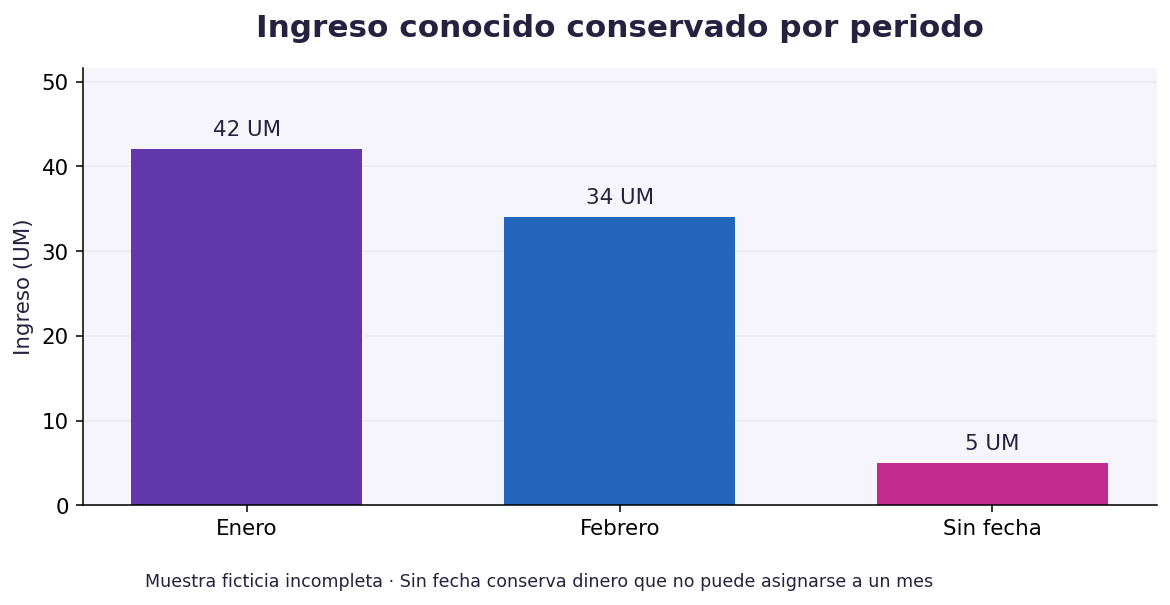

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
barras = ax.bar(resumen_cafe["Periodo"], resumen_cafe["Ingreso"], color=COLORES_PYM[:3], width=0.62)
ax.bar_label(barras, labels=[f"{valor:.0f} UM" for valor in resumen_cafe["Ingreso"]], padding=5)
ax.set_title("Ingreso conocido conservado por periodo", fontsize=16, fontweight="bold", pad=16)
ax.set_ylabel("Ingreso (UM)")
ax.set_ylim(0, resumen_cafe["Ingreso"].max() * 1.23)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
fig.text(0.13, 0.01, "Muestra ficticia incompleta · Sin fecha conserva dinero que no puede asignarse a un mes", fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


## 14. SQL: extraemos febrero para llevar

`WHERE` filtra ventas antes de resumir. `BETWEEN` incluye ambos extremos; aquí es
adecuado porque las fechas son textos ISO completos, sin horas. T09 tiene fecha `NULL`
y queda fuera de la selección mensual, pero permanece en el ingreso global.


In [17]:
filtro_febrero_sql = """
FROM ventas_cafe
WHERE Fecha BETWEEN '2026-02-01' AND '2026-02-28'
  AND Modalidad = 'Takeaway'
"""
cafe_febrero = consultar("SELECT VentaID, Producto, Cantidad, Ingreso, Fecha " +
                        filtro_febrero_sql + " ORDER BY VentaID")
cafe_febrero_control = consultar("SELECT COUNT(*) AS Ventas, SUM(Ingreso) AS Ingreso " + filtro_febrero_sql)
display(cafe_febrero)
display(cafe_febrero_control)
assert set(cafe_febrero["VentaID"]) == set(febrero_para_llevar["Transaction_ID"])
assert np.isclose(cafe_febrero_control.loc[0, "Ingreso"], febrero_para_llevar["Total_Spent"].sum())
assert int(cafe_febrero_control.loc[0, "Ventas"]) == len(febrero_para_llevar)


,VentaID,Producto,Cantidad,Ingreso,Fecha
0,T06,Cookie,5,5.0,2026-02-02
1,T11,Smoothie,3,12.0,2026-02-16


,Ventas,Ingreso
0,2,17.0


## 15. Un mismo cruce puede responder preguntas distintas

Operaciones necesita ver **todos los productos del menú**, aunque no tengan actividad.
Para esa pregunta dejamos el catálogo a la izquierda. Primero resumimos ventas por
producto en una subconsulta; después unimos ese resumen con `LEFT JOIN`.

| Antes de unir | Unidad de una fila | Llave |
|---|---|---|
| `menu_cafe` | Un producto del menú. | `Producto` único. |
| Subconsulta de ventas | Todas las ventas de un producto resumidas. | `Producto` único. |
| Resultado del cruce | Un producto del menú con actividad cuando hay coincidencia. | `Producto`. |

`USING (Producto)` indica que la columna llave tiene el mismo nombre en ambos lados.
Muffin permanecerá con métricas `NULL`: sin ventas registradas en esta muestra.


In [18]:
query_menu = """
SELECT m.Producto, m.PrecioMenu,
       r.Ventas, r.UnidadesConocidas, ROUND(r.Ingreso, 2) AS Ingreso
FROM menu_cafe AS m
LEFT JOIN (
    SELECT Producto, COUNT(*) AS Ventas,
           SUM(Cantidad) AS UnidadesConocidas,
           SUM(Ingreso) AS Ingreso
    FROM ventas_cafe
    GROUP BY Producto
) AS r USING (Producto)
ORDER BY Ingreso DESC, m.Producto ASC
"""
cafe_menu = consultar(query_menu)
display(cafe_menu)
assert len(cafe_menu) == len(df_menu)
assert cafe_menu["Producto"].is_unique
assert pd.isna(cafe_menu.loc[cafe_menu["Producto"] == "Muffin", "Ventas"].iloc[0])
print("Ingreso explicado por productos del menú:", cafe_menu["Ingreso"].sum(), "UM")


,Producto,PrecioMenu,Ventas,UnidadesConocidas,Ingreso
0,Sandwich,4.0,2.0,3.0,12.0
1,Smoothie,4.0,1.0,3.0,12.0
2,Coffee,2.0,2.0,5.0,10.0
3,Cake,3.0,1.0,3.0,9.0
4,Tea,1.5,2.0,6.0,9.0
5,Juice,3.0,1.0,2.0,6.0
6,Cookie,1.0,1.0,5.0,5.0
7,Salad,5.0,1.0,1.0,5.0
8,Muffin,2.5,NaN,NaN,NaN


Ingreso explicado por productos del menú: 68.0 UM


🔥 **¿El reporte del menú explica todo el ingreso?** Explica 68 UM de productos
identificados. No contiene los 13 UM de ventas con producto desconocido, porque
`Desconocido` no es un producto del catálogo. Conservar todos los productos del menú
y conservar todas las ventas son preguntas diferentes.

No sustituimos las métricas de Muffin por ceros: mantenemos la falta de coincidencia
visible. Tampoco llamamos a los 68 UM «ingreso global», porque su cobertura es menor.


## 16. Auditamos INNER JOIN y LEFT JOIN desde las ventas

Para revisar el cierre global, la tabla que debe conservarse es `ventas_cafe`.
Comparamos el cruce interno con uno izquierdo, usando `ON` para escribir la igualdad
de forma explícita. El menú tiene una llave única: por ello el `LEFT JOIN` conserva
una fila por venta y no multiplica sus ingresos.


In [19]:
query_inner = """
SELECT COUNT(*) AS Ventas, SUM(v.Ingreso) AS Ingreso
FROM ventas_cafe AS v
INNER JOIN menu_cafe AS m ON v.Producto = m.Producto
"""
query_left = """
SELECT COUNT(*) AS Ventas, SUM(v.Ingreso) AS Ingreso
FROM ventas_cafe AS v
LEFT JOIN menu_cafe AS m ON v.Producto = m.Producto
"""
cafe_inner = consultar(query_inner)
cafe_left = consultar(query_left)
cafe_desconocido = consultar("""
SELECT COUNT(*) AS Ventas, SUM(Ingreso) AS Ingreso
FROM ventas_cafe WHERE Producto = 'Desconocido'
""")
auditoria_join = pd.DataFrame([
    {"Cobertura": "Global preparado", **cafe_global[["Ventas", "Ingreso"]].iloc[0].to_dict()},
    {"Cobertura": "INNER JOIN con menú", **cafe_inner.iloc[0].to_dict()},
    {"Cobertura": "LEFT JOIN desde ventas", **cafe_left.iloc[0].to_dict()},
    {"Cobertura": "Producto desconocido", **cafe_desconocido.iloc[0].to_dict()}
])
display(auditoria_join)
assert cafe_left.loc[0, "Ventas"] == cafe_global.loc[0, "Ventas"]
assert np.isclose(cafe_left.loc[0, "Ingreso"], cafe_global.loc[0, "Ingreso"])
assert cafe_left.loc[0, "Ventas"] - cafe_inner.loc[0, "Ventas"] == cafe_desconocido.loc[0, "Ventas"]
assert np.isclose(cafe_left.loc[0, "Ingreso"] - cafe_inner.loc[0, "Ingreso"], cafe_desconocido.loc[0, "Ingreso"])
assert np.isclose(cafe_menu["Ingreso"].sum() + cafe_desconocido.loc[0, "Ingreso"], ingreso_global_python)
print("Conciliación del menú: identificados + desconocidos = ingreso global conservado.")


,Cobertura,Ventas,Ingreso
0,Global preparado,13.0,81.0
1,INNER JOIN con menú,11.0,68.0
2,LEFT JOIN desde ventas,13.0,81.0
3,Producto desconocido,2.0,13.0


Conciliación del menú: identificados + desconocidos = ingreso global conservado.


### 👀 La decisión y su impacto ya están comprobados

El `INNER JOIN` deja 11 ventas y 68 UM. El `LEFT JOIN` desde ventas conserva las
13 ventas y 81 UM. La diferencia coincide con 2 ventas de producto desconocido y
13 UM. El dinero no desapareció del archivo: lo eliminaba la cobertura del cruce.

Este es un control cotidiano del analista: contar filas, revisar llaves y conciliar
importes **antes y después de una unión**, aunque la consulta no presente errores.


## 17. 🤖 Pedimos ayuda a la IA con un encargo que podemos verificar

Un prompt útil incorpora la pregunta del área, la unidad del dato, las reglas y los
controles. Podemos pedir una explicación o una revisión del código sin enviarle
información de una empresa real. Aquí trabajamos únicamente con datos ficticios.

> Actúa como apoyo de un analista jr. Tengo `ventas_cafe`, una fila por venta, con
> `VentaID` único, `Producto`, `Cantidad` e `Ingreso`. `menu_cafe` tiene `Producto`
> único y `PrecioMenu`. Hay ventas de producto desconocido y un producto sin ventas.
> Revisa cómo un INNER JOIN puede reducir el ingreso del cierre. Propón una consulta
> de control que conserve ventas y explica cómo comprobarla. No inventes productos,
> cantidades ni ingresos, y usa SELECT, SUM, COUNT y LEFT JOIN vistos en el curso.

**Ejemplo de propuesta revisada:** «Deja ventas a la izquierda del LEFT JOIN y compara
su conteo e ingreso con el global». Ya la resolvimos arriba y ahora la comprobamos
también a nivel de identificador. Esta es una demostración local; no llamamos a una API.


In [20]:
control_ia = consultar("""
SELECT v.VentaID, COUNT(*) AS FilasDespues
FROM ventas_cafe AS v
LEFT JOIN menu_cafe AS m ON v.Producto = m.Producto
GROUP BY v.VentaID
HAVING COUNT(*) <> 1
""")
assert control_ia.empty
assert cafe_left.loc[0, "Ventas"] == 13
assert np.isclose(cafe_left.loc[0, "Ingreso"], 81.0)
print("Revisión de la propuesta: cada venta aporta una sola fila; conteo e ingreso coinciden.")


Revisión de la propuesta: cada venta aporta una sola fila; conteo e ingreso coinciden.


## 18. Preparamos archivos que otra persona pueda revisar

Guardamos el cierre por periodo, el menú y las bitácoras. Los CSV llevan encabezados
y no incluyen el índice de pandas. Releemos los principales para verificar que lo
exportado conserva las columnas, las filas y las cifras que acabamos de revisar.

En Colab aparecen en el panel **Archivos**, dentro de `pym_cafeteria/entregables`.
Desde allí se pueden descargar. La base `analisis.db` queda en `pym_cafeteria`.


In [21]:
ruta_cierre_sql = carpeta_salida / "cafe_cierre_periodos_sql.csv"
ruta_menu_sql = carpeta_salida / "cafe_menu_sql.csv"
cafe_periodos.to_csv(ruta_cierre_sql, index=False)
cafe_menu.to_csv(ruta_menu_sql, index=False)
auditoria_preparacion.to_csv(carpeta_salida / "cafe_auditoria_preparacion.csv", index=False)
auditoria_join.to_csv(carpeta_salida / "cafe_auditoria_uniones.csv", index=False)
df_excluidas[["Transaction_ID", "Item", "Total_Spent", "Motivo"]].to_csv(
    carpeta_salida / "cafe_registros_apartados.csv", index=False)
cierre_archivo = pd.read_csv(ruta_cierre_sql)
menu_archivo = pd.read_csv(ruta_menu_sql)
pd.testing.assert_frame_equal(cierre_archivo, cafe_periodos, check_dtype=False)
pd.testing.assert_frame_equal(menu_archivo, cafe_menu, check_dtype=False)
assert np.isclose(cierre_archivo["Ingreso"].sum(), ingreso_global_python)
print("Archivos generados y principales releídos:")
for archivo in sorted(carpeta_salida.glob("*.csv")):
    print("•", archivo.name)


Archivos generados y principales releídos:
• cafe_auditoria_preparacion.csv
• cafe_auditoria_uniones.csv
• cafe_cierre_periodos_sql.csv
• cafe_menu_sql.csv
• cafe_registros_apartados.csv
• resumen_operaciones_cafe.csv


## 19. La entrega de trabajo: cifras, alcance y acción

La persona de operaciones necesita una respuesta breve y verificable. Construimos
el mensaje desde las tablas para mantenerlo alineado con los resultados.
El cierre entregado corresponde al **ingreso conocido conservado**: todavía existe
una transacción cuyo ingreso no pudimos recuperar.


In [22]:
ventas_total = int(cafe_global.loc[0, "Ventas"])
ingreso_total = float(cafe_global.loc[0, "Ingreso"])
ingreso_sin_fecha = float(sin_fecha["Total_Spent"].sum())
ventas_febrero = int(cafe_febrero_control.loc[0, "Ventas"])
ingreso_febrero = float(cafe_febrero_control.loc[0, "Ingreso"])
ingreso_no_identificado = float(cafe_desconocido.loc[0, "Ingreso"])
mensaje_operaciones = (
    f"El cierre de la muestra conserva {ventas_total} ventas y {ingreso_total:.2f} UM; "
    f"{ingreso_sin_fecha:.2f} UM no pueden asignarse a un mes, y febrero para llevar reúne "
    f"{ventas_febrero} ventas por {ingreso_febrero:.2f} UM. "
    f"Retiramos una carga duplicada y apartamos T07 por ingreso irrecuperable; conservamos "
    f"T09 sin fecha y T10 sin cantidad, y un INNER JOIN con el menú excluiría "
    f"{ingreso_no_identificado:.2f} UM de productos desconocidos. "
    "Conviene corregir la captura de fecha, producto y cantidad; esta muestra incompleta "
    "no permite afirmar una tendencia mensual ni cuantificar el ingreso de T07."
)
display(Markdown("### Mensaje a operaciones\n\n" + mensaje_operaciones))


### Mensaje a operaciones

El cierre de la muestra conserva 13 ventas y 81.00 UM; 5.00 UM no pueden asignarse a un mes, y febrero para llevar reúne 2 ventas por 17.00 UM. Retiramos una carga duplicada y apartamos T07 por ingreso irrecuperable; conservamos T09 sin fecha y T10 sin cantidad, y un INNER JOIN con el menú excluiría 13.00 UM de productos desconocidos. Conviene corregir la captura de fecha, producto y cantidad; esta muestra incompleta no permite afirmar una tendencia mensual ni cuantificar el ingreso de T07.

## 20. 🔥 Uniendo las piezas del proyecto

| Tema del curso | Dónde cobró sentido en el trabajo |
|---|---|
| Exploración, tipos y faltantes | Detectamos que el archivo no estaba listo para calcular. |
| Funciones, ciclos, `map`, `fillna`, fechas | Reunimos decisiones de limpieza que se pueden repetir. |
| Filtros, sumas y exportación Python | Respondimos el cierre y febrero para llevar con herramientas conocidas. |
| SQLite, `to_sql` y conexiones | Dejamos una versión validada disponible para consultas. |
| `WHERE`, `BETWEEN`, `GROUP BY`, `COUNT`, `SUM`, `ROUND` | Separamos filas, cantidades conocidas e ingreso al nivel requerido. |
| Subconsultas, `LEFT`/`INNER`, `ON`/`USING` | Elegimos la cobertura y comprobamos que el cruce no perdiera dinero. |
| Conciliación y comunicación | Sostuvimos las cifras y explicamos qué sigue sin conocerse. |

**El papel de Python:** preparar un insumo trazable, automatizar reglas y revisar/exportar.
**El papel de SQL:** extraer el segmento, resumir y relacionar tablas al nivel correcto.
**Nuestro papel como analistas:** definir la pregunta, justificar decisiones y comprobar
que una cifra representa lo que el área cree que representa.

### Cuando llegue el siguiente corte

El recorrido ya deja resuelto cómo trabajar: conservar el nuevo insumo, comprobar su
contrato, aplicar la función cuando las reglas sigan vigentes, revisar la bitácora,
restablecer las tablas de este caso, repetir los controles y emitir una nueva nota.
Si cambia una regla del negocio, primero la aclaramos y documentamos.

**Una idea para llevarnos:** un reporte confiable puede contener desconocidos.
La responsabilidad del analista es hacerlos visibles y explicar cómo afectan la respuesta.

---
**Materiales de origen:** `Casos_de_uso_C3 (1).ipynb` (forma de acompañamiento y reflexión),
`Copia_de_Tarea_2_intermedio_202610 (2)(1).ipynb` (consignas y datos de la tarea Python)
y `Tarea_3_SQL_Contexto_Laboral_PyM.ipynb` (continuidad SQL y catálogo del menú).
Esta guía desarrolla las consignas originales; no reproduce las respuestas añadidas
en la copia del estudiante.
